# Notebook 4: Feature engineering and PCA

**Input:** `data/weekly_panel.csv` (made by Notebook 2): one price per market per week, core markets, 2010-2026
**Outputs:**
- `data/features.csv`: one row per market-week with every feature, the targets, and the train/test label
- `data/feature_dictionary.csv`: what each feature means and why it is included (for the report)
- `data/pca_loadings.csv` and `data/pca_variance.csv`: the PCA results

**The prediction task.** A farmer is standing in week *t* with a harvested crop. The question is: *will the price in
my market be higher in h weeks than it is today, and by how much?* So the target is the **log price change** over the
next h weeks, for h = 4, 8 and 12 weeks (about 1, 2 and 3 months). Notebook 5 forecasts it; Notebook 6 turns the
forecast into a sell-or-store decision.

**The golden rule of this notebook: no peeking into the future.** Every feature for week *t* uses only prices up to
and including week *t*. Anything learned from the data (seasonal patterns, PCA) is learned from the **training
period only**, then applied to the test period.

**Steps**
1. Load the panel and fix the 70/30 train/test split in time (with a gap so no training target looks into the test period)
2. Build the targets
3. Build the features, in eight groups
4. Check feature quality: completeness and redundancy
5. Check feature relevance: which features carry information about future prices, and does it hold in the test period?
6. PCA on the market-by-week price matrix (research question RQ2: how closely do mandis move together?)
7. Save

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA

PANEL_FILE = "../data/weekly_panel.csv"
SEED = 42
HORIZONS = [4, 8, 12]
MAX_H = max(HORIZONS)

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_COLOR = {"Maize": BLUE, "Onion": ORANGE}
CROPS = ["Onion", "Maize"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 160)

DIVISION = {
    "Bangalore": "Bengaluru", "Kolar": "Bengaluru", "Tumkur": "Bengaluru", "Chitradurga": "Bengaluru",
    "Davangere": "Bengaluru", "Shimoga": "Bengaluru",
    "Mysore": "Mysuru", "Mandya": "Mysuru", "Chamrajnagar": "Mysuru", "Hassan": "Mysuru",
    "Madikeri(Kodagu)": "Mysuru", "Chikmagalur": "Mysuru", "Mangalore(Dakshin Kannad)": "Mysuru", "Udupi": "Mysuru",
    "Belgaum": "Belagavi", "Bagalkot": "Belagavi", "Bijapur": "Belagavi", "Dharwad": "Belagavi",
    "Gadag": "Belagavi", "Haveri": "Belagavi", "Karwar(Uttar Kannad)": "Belagavi",
    "Kalburgi": "Kalaburagi", "Bidar": "Kalaburagi", "Yadgiri": "Kalaburagi", "Raichur": "Kalaburagi",
    "Koppal": "Kalaburagi", "Bellary": "Kalaburagi",
}
DIV_ORDER = ["Bengaluru", "Mysuru", "Belagavi", "Kalaburagi"]
DIV_COLOR = dict(zip(DIV_ORDER, [ORANGE, VIOLET, AQUA, BLUE]))

## 1. Load the panel and fix the train/test split

**Why not a random 70/30 split?** Prices next week are very close to prices this week. If weeks were shuffled at
random, the model would be trained on weeks on both sides of every test week and would effectively be told the answer.
Its test score would look excellent but would mean nothing for a farmer, who only ever has the past.

**What is done instead (and how it meets the 70/30 requirement):**
- A **chronological 70/30 split**: the earliest 70% of usable market-weeks are training data, the latest 30% are test data.
- A **gap (purge) of 12 weeks** before the cut: a training row in week *t* has a target that looks 12 weeks ahead.
  If *t* is just before the cut, that target lies inside the test period. Those rows are dropped from training.
- Notebook 5 also runs a random 70/30 split, only to show how misleading it is.

In [2]:
panel = pd.read_csv(PANEL_FILE, parse_dates=["week"])
panel["division"] = panel["district"].map(DIVISION)
panel = panel.sort_values(["commodity", "market", "week"]).reset_index(drop=True)
print(f"Rows: {len(panel):,} | markets: {panel.groupby('commodity')['market'].nunique().to_dict()} | "
      f"weeks: {panel['week'].nunique()} ({panel['week'].min().date()} to {panel['week'].max().date()})")
print("Every market has every week (missing prices are NaN):",
      panel.groupby(["commodity", "market"]).size().nunique() == 1)

panel["log_price"] = np.log(panel["price_filled"])
by_market = panel.groupby(["commodity", "market"])
for h in HORIZONS:
    panel[f"target_{h}w"] = by_market["log_price"].shift(-h) - panel["log_price"]
    # was the price really reported at both ends (not filled in by Notebook 2)?
    panel[f"target_{h}w_observed"] = panel["price"].notna() & by_market["price"].shift(-h).notna()

# Find the cut week so that, after the 12-week purge, 70% of usable rows are training rows
usable = panel["log_price"].notna() & panel[f"target_{MAX_H}w"].notna()
weeks = np.sort(panel.loc[usable, "week"].unique())
for cut in weeks:
    train_n = (usable & (panel["week"] + pd.Timedelta(weeks=MAX_H) < cut)).sum()
    test_n = (usable & (panel["week"] >= cut)).sum()
    if train_n / (train_n + test_n) >= 0.70:
        CUT = pd.Timestamp(cut)
        break

panel["split"] = np.select(
    [panel["week"] + pd.Timedelta(weeks=MAX_H) < CUT, panel["week"] < CUT],
    ["train", "gap (purged)"], default="test")
share = panel.loc[usable, "split"].value_counts()
print(f"\nCut week: {CUT.date()}  (training targets all end before this week)")
print((share / share[["train", "test"]].sum() * 100).round(1).rename("% of usable rows (train + test = 100)").to_string())

Rows: 56,100 | markets: {'Maize': 48, 'Onion': 18} | weeks: 850 (2010-01-04 to 2026-04-13)
Every market has every week (missing prices are NaN): True

Cut week: 2019-11-18  (training targets all end before this week)
split
train           70.1
test            29.9
gap (purged)     1.8


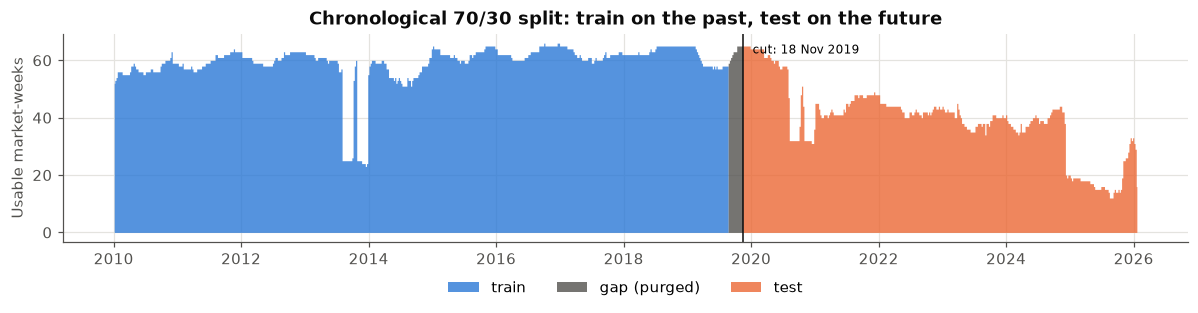

In [3]:
counts = panel[usable].groupby(["week", "split"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3))
split_color = {"train": BLUE, "gap (purged)": MUTED, "test": ORANGE}
for s in ["train", "gap (purged)", "test"]:
    if s in counts:
        ax.fill_between(counts.index, 0, counts[s], step="mid", color=split_color[s], alpha=0.8, linewidth=0, label=s)
ax.axvline(CUT, color=INK, linewidth=1)
ax.annotate(f"cut: {CUT:%d %b %Y}", (CUT, ax.get_ylim()[1] * 0.9), textcoords="offset points", xytext=(6, 0), fontsize=8)
ax.set_ylabel("Usable market-weeks")
ax.set_title("Chronological 70/30 split: train on the past, test on the future")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

**Reading the chart.** Training covers 2010 to late 2019; the test period starts in November 2019, in the middle
of the **2019 onion crisis**, and runs to April 2026, so it includes COVID-19 (2020) and the 2023-2024 onion spikes. It is a
hard test: the models must cope with events they have never seen. The number of reporting markets falls in recent
years (Notebook 3), so the test period has fewer rows per week.

## 2. The targets

`target_hw` = log(price in week t+h) − log(price in week t). A value of 0.10 means the price rose by about 10.5%.
Log changes are used because (Notebook 3) prices are skewed but log changes are roughly symmetric, and because a rise
of +50% and a fall of −33% cancel out on the log scale, just as they do for a farmer's money.

`target_hw_observed` marks rows where both prices were actually reported. Models may train on filled values, but
**final scores in Notebook 5 use observed targets only**, so the filling from Notebook 2 cannot flatter the results.

,crop,horizon (weeks),rows,observed at both ends %,median change %,SD (log),price rose %,rose > 20 %,fell > 20 %
0,Onion,4,13235,81.65,0.00,0.30,47.21,24.49,23.36
1,Onion,8,12927,81.46,1.08,0.44,50.34,33.66,30.09
2,Onion,12,12709,81.14,4.55,0.54,52.42,39.29,32.62
3,Maize,4,32086,75.07,0.35,0.10,51.28,2.95,3.80
4,Maize,8,31106,74.38,1.43,0.12,55.17,5.75,6.29
5,Maize,12,30457,74.13,2.13,0.14,56.33,9.47,8.91


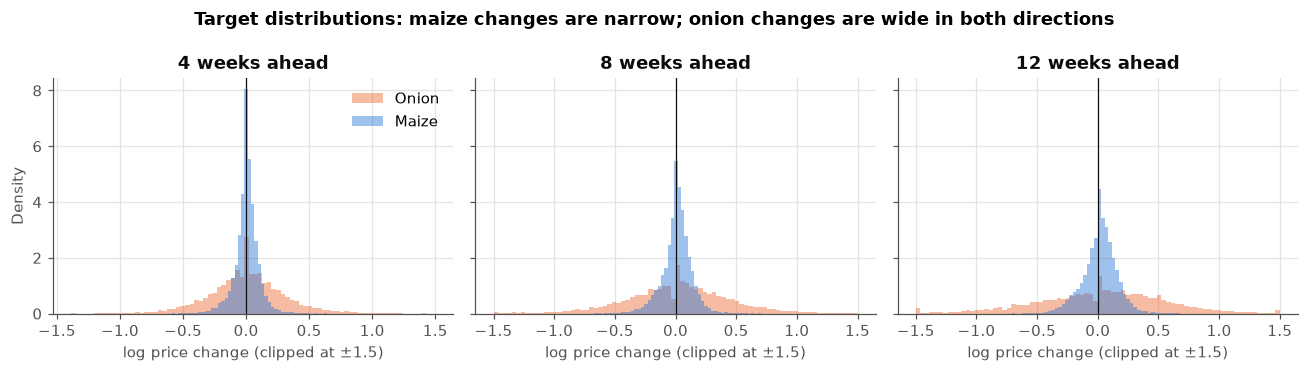

In [4]:
rows = []
for crop in CROPS:
    for h in HORIZONS:
        t = panel.loc[(panel["commodity"] == crop) & panel[f"target_{h}w"].notna(), [f"target_{h}w", f"target_{h}w_observed"]]
        y = t[f"target_{h}w"]
        rows.append({"crop": crop, "horizon (weeks)": h, "rows": len(y), "observed at both ends %": 100 * t[f"target_{h}w_observed"].mean(),
                     "median change %": 100 * np.expm1(y.median()), "SD (log)": y.std(),
                     "price rose %": 100 * (y > 0).mean(), "rose > 20 %": 100 * (y > np.log(1.2)).mean(),
                     "fell > 20 %": 100 * (y < np.log(1 / 1.2)).mean()})
display(pd.DataFrame(rows).round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, h in zip(axes, HORIZONS):
    for crop in CROPS:
        y = panel.loc[panel["commodity"] == crop, f"target_{h}w"].dropna()
        ax.hist(y.clip(-1.5, 1.5), bins=80, density=True, histtype="stepfilled", alpha=0.45, color=CROP_COLOR[crop], label=crop)
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_title(f"{h} weeks ahead"); ax.set_xlabel("log price change (clipped at ±1.5)")
axes[0].set_ylabel("Density"); axes[0].legend(frameon=False)
fig.suptitle("Target distributions: maize changes are narrow; onion changes are wide in both directions", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Feature engineering

Each feature answers a question a trader or farmer would ask. All are computed **per market**, from that market's
past prices (plus the statewide median, which is also known in week *t*).

| Group | Features | The question it answers |
| --- | --- | --- |
| A. Calendar | `week_of_year`, `woy_sin`, `woy_cos`, `month` | Where are we in the crop year? (sin/cos make week 52 sit next to week 1) |
| B. Momentum | `chg_1w`, `chg_4w`, `chg_12w`, `chg_26w`, `chg_52w` | Has the price been rising or falling, and for how long? |
| C. Level vs normal | `vs_52w_mean`, `vs_seasonal_norm`, `range_pos_52w` | Is today's price unusually high or low? (high prices tend to fall back) |
| D. Seasonal expectation | `seas_exp_{h}w_crop`, `seas_exp_{h}w_mkt` | Historically, how much does the price change from this week over the next h weeks? (learned from training years only) |
| E. Combined | `room_to_rise_12w` | Seasonal expectation minus how far the price is already above normal |
| F. Risk | `vol_8w`, `vol_26w` | How jumpy has this market been recently? |
| G. Spatial | `premium`, `premium_52w`, `state_chg_4w`, `division`, `market` | Is this market dear or cheap compared with the state, and where is the state price heading? |
| H. Data quality | `imputed_share_8w`, `was_imputed` | How much of the recent history was filled in rather than reported? |
| PCA | `pc1`, `pc2`, `pc3` | Statewide co-movement factors (Section 6) |

**Not done here:** scaling and one-hot encoding of `division` and `market`. They are fitted inside the model pipelines
in Notebook 5, on training rows only.

In [5]:
g = panel.groupby(["commodity", "market"])

# A. Calendar
panel["week_of_year"] = panel["week"].dt.isocalendar().week.astype(int).clip(upper=52)
panel["woy_sin"] = np.sin(2 * np.pi * panel["week_of_year"] / 52)
panel["woy_cos"] = np.cos(2 * np.pi * panel["week_of_year"] / 52)
panel["month"] = panel["week"].dt.month

# B. Momentum: log change over the past k weeks
for k in [1, 4, 12, 26, 52]:
    panel[f"chg_{k}w"] = panel["log_price"] - g["log_price"].shift(k)

# C. Level compared with normal
panel["vs_52w_mean"] = panel["log_price"] - g["log_price"].transform(lambda s: s.rolling(52, min_periods=26).mean())
same_week_before = pd.concat([g["log_price"].shift(52 * y) for y in [1, 2, 3]], axis=1)
panel["vs_seasonal_norm"] = (panel["log_price"] - same_week_before.mean(axis=1)).where(same_week_before.notna().sum(axis=1) >= 2)
roll_min = g["log_price"].transform(lambda s: s.rolling(52, min_periods=26).min())
roll_max = g["log_price"].transform(lambda s: s.rolling(52, min_periods=26).max())
panel["range_pos_52w"] = ((panel["log_price"] - roll_min) / (roll_max - roll_min)).where(roll_max > roll_min)

# F. Risk: spread of weekly changes
weekly_change = g["log_price"].diff()
panel["vol_8w"] = weekly_change.groupby([panel["commodity"], panel["market"]]).transform(lambda s: s.rolling(8, min_periods=4).std())
panel["vol_26w"] = weekly_change.groupby([panel["commodity"], panel["market"]]).transform(lambda s: s.rolling(26, min_periods=13).std())

# G. Spatial
panel["log_state"] = np.log(panel["state_median"])
panel["premium"] = panel["log_price"] - panel["log_state"]
panel["premium_52w"] = g["premium"].transform(lambda s: s.rolling(52, min_periods=26).mean())
panel["state_chg_4w"] = panel["log_state"] - g["log_state"].shift(4)

# H. Data quality
panel["imputed_share_8w"] = g["was_imputed"].transform(lambda s: s.astype(float).rolling(8, min_periods=1).mean())
print("Groups A, B, C, F, G, H done.")

Groups A, B, C, F, G, H done.


### Group D: seasonal expectation, learned from the training years only

For each crop and week of the year, the **median log change over the next h weeks** in the training period, using only
observed (not filled) prices. Week-to-week noise is reduced with a 5-week moving average around the calendar (week 52
wraps round to week 1). A market-specific version is computed the same way and used where the market has at least
5 training years for that week; otherwise the crop-wide value is used.

This is the most important feature, and the easiest one to leak: if it were computed from all years, it would contain
the test-period prices it is meant to predict. Here it is computed from rows labelled `train` only.

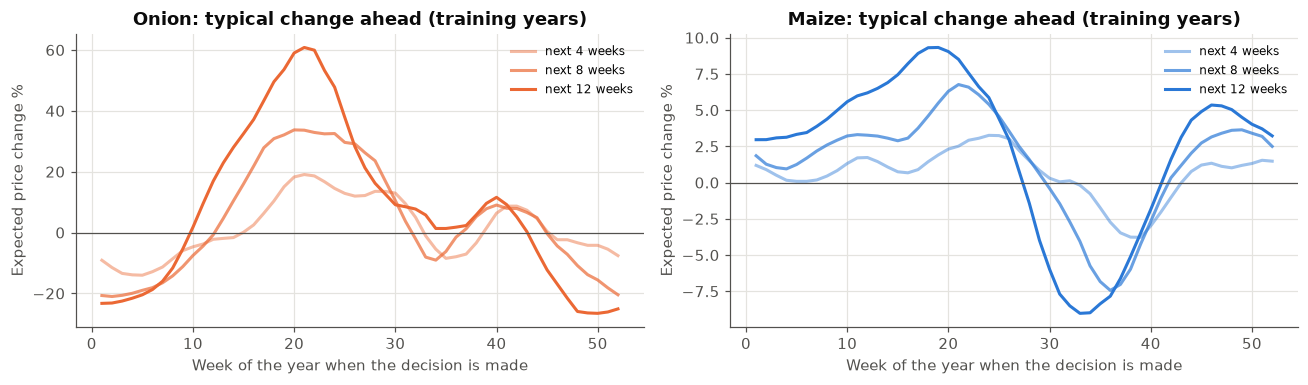

In [6]:
def circular_smooth(s, window=5):
    # moving average over week of year, wrapping week 52 round to week 1
    s = s.reindex(range(1, 53))
    padded = pd.concat([s.iloc[-window:], s, s.iloc[:window]])
    return padded.rolling(window, center=True, min_periods=1).mean().iloc[window:-window]

train_rows = panel[panel["split"] == "train"]
for h in HORIZONS:
    ok = train_rows[train_rows[f"target_{h}w_observed"]]
    crop_curve = {crop: circular_smooth(ok[ok["commodity"] == crop].groupby("week_of_year")[f"target_{h}w"].median())
                  for crop in CROPS}
    crop_table = pd.concat(crop_curve, names=["commodity", "week_of_year"]).rename(f"seas_exp_{h}w_crop")
    panel = panel.join(crop_table, on=["commodity", "week_of_year"])

    mk = ok.groupby(["commodity", "market", "week_of_year"])[f"target_{h}w"].agg(["median", "size"])
    mk_median = mk["median"].where(mk["size"] >= 5)
    smoothed = (mk_median.groupby(level=["commodity", "market"], group_keys=False)
                .apply(lambda s: circular_smooth(s.droplevel([0, 1])).set_axis(
                    pd.MultiIndex.from_product([[s.index[0][0]], [s.index[0][1]], range(1, 53)],
                                               names=["commodity", "market", "week_of_year"]))))
    panel = panel.join(smoothed.rename(f"seas_exp_{h}w_mkt"), on=["commodity", "market", "week_of_year"])
    panel[f"seas_exp_{h}w_mkt"] = panel[f"seas_exp_{h}w_mkt"].fillna(panel[f"seas_exp_{h}w_crop"])

# E. Combined feature: expected seasonal rise minus how far the price already is above its normal level
panel["room_to_rise_12w"] = panel["seas_exp_12w_mkt"] - panel["vs_seasonal_norm"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, crop in zip(axes, CROPS):
    curve = panel[panel["commodity"] == crop].groupby("week_of_year")[[f"seas_exp_{h}w_crop" for h in HORIZONS]].first()
    for h, a in zip(HORIZONS, [0.45, 0.7, 1.0]):
        ax.plot(curve.index, 100 * np.expm1(curve[f"seas_exp_{h}w_crop"]), color=CROP_COLOR[crop], alpha=a, linewidth=2, label=f"next {h} weeks")
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_xlabel("Week of the year when the decision is made"); ax.set_ylabel("Expected price change %")
    ax.set_title(f"{crop}: typical change ahead (training years)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Reading the chart.** For onion, a decision made in spring (weeks 12-20) has historically been followed by
rising prices over the next 12 weeks, while a decision made in late autumn has been followed by falling prices. For
maize the same shape exists but is much flatter. This is the seasonal knowledge a farmer's experience provides; the
models in Notebook 5 must beat it to be useful.

## 4. Feature quality: completeness and redundancy

In [7]:
FEATURES_NUM = ["woy_sin", "woy_cos", "chg_1w", "chg_4w", "chg_12w", "chg_26w", "chg_52w",
                "vs_52w_mean", "vs_seasonal_norm", "range_pos_52w",
                "seas_exp_4w_crop", "seas_exp_8w_crop", "seas_exp_12w_crop",
                "seas_exp_4w_mkt", "seas_exp_8w_mkt", "seas_exp_12w_mkt", "room_to_rise_12w",
                "vol_8w", "vol_26w", "premium", "premium_52w", "state_chg_4w", "imputed_share_8w"]

has_price = panel["log_price"].notna()
complete = (panel.loc[has_price, FEATURES_NUM].notna().mean() * 100).round(1).sort_values()
print("% of market-weeks with a price where each feature is available (lowest first):")
print(complete.head(8).to_string())
print(f"\nRows with a price and every feature: {panel.loc[has_price, FEATURES_NUM].notna().all(axis=1).mean() * 100:.1f}%")
print("Most gaps are in the first 2-3 years of each market, before enough history exists for 52-week and 3-year features.")

% of market-weeks with a price where each feature is available (lowest first):
vs_seasonal_norm    81.8
room_to_rise_12w    81.8
chg_52w             86.3
chg_26w             89.2
chg_12w             92.3
range_pos_52w       93.0
premium_52w         93.0
vs_52w_mean         93.0

Rows with a price and every feature: 69.9%
Most gaps are in the first 2-3 years of each market, before enough history exists for 52-week and 3-year features.


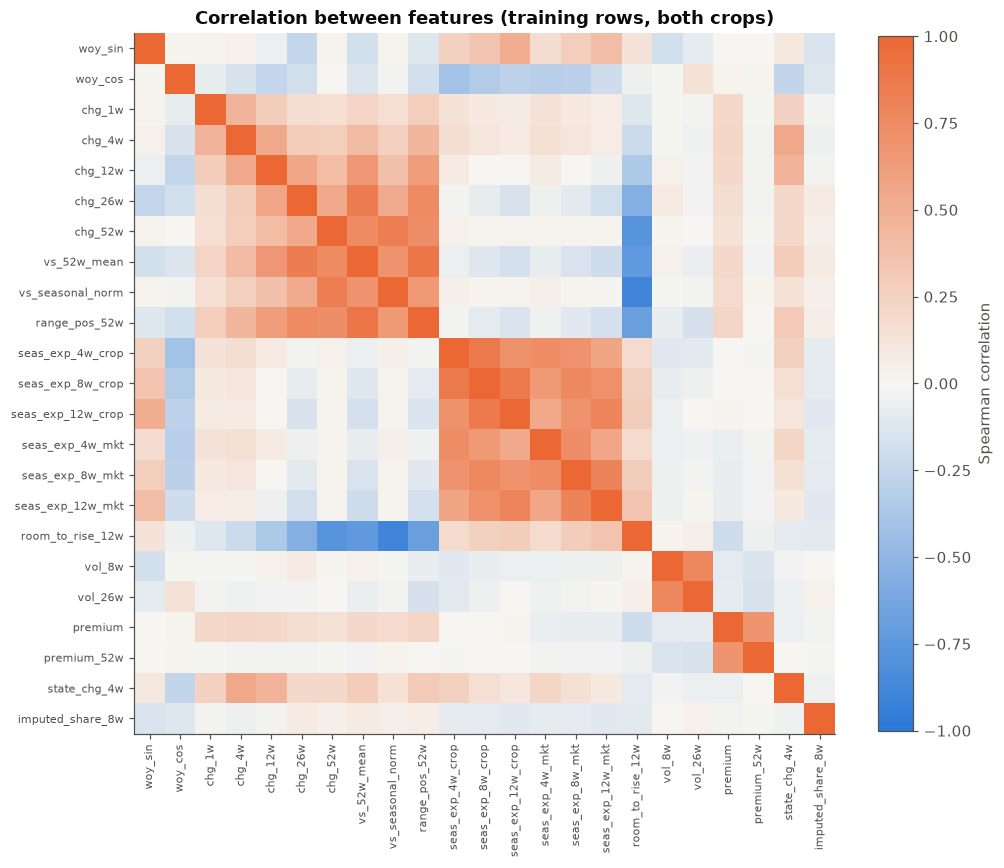

Feature pairs with |correlation| >= 0.8:
vs_52w_mean       range_pos_52w        0.90
vs_seasonal_norm  room_to_rise_12w    -0.89
seas_exp_4w_crop  seas_exp_8w_crop     0.87
seas_exp_8w_crop  seas_exp_12w_crop    0.86
chg_26w           vs_52w_mean          0.85
chg_52w           vs_seasonal_norm     0.84
seas_exp_8w_mkt   seas_exp_12w_mkt     0.80


In [8]:
corr = panel.loc[panel["split"] == "train", FEATURES_NUM].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr.values, cmap=LinearSegmentedColormap.from_list("neg_pos", [BLUE, "#f7f6f2", ORANGE]), vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES_NUM))); ax.set_xticklabels(FEATURES_NUM, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES_NUM))); ax.set_yticklabels(FEATURES_NUM, fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.04, label="Spearman correlation")
ax.set_title("Correlation between features (training rows, both crops)")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() >= 0.8].sort_values(key=np.abs, ascending=False)
print("Feature pairs with |correlation| >= 0.8:")
print(pairs.round(2).to_string())

**What this shows.** Several features carry overlapping information: the seasonal expectations for 4, 8 and 12
weeks are strongly related, and so are the crop-wide and market-specific versions; the 52-week level features overlap
with each other. This redundancy (multicollinearity) is a problem for plain linear regression, whose coefficients
become unstable. Notebook 5 handles it with **Ridge regression** (which shrinks correlated coefficients) and with
tree models (which are not affected), and compares models with and without PCA-reduced inputs.

## 5. Feature relevance: do the features say anything about future prices?

Spearman correlation between each feature and the 12-week target, measured separately in the **training** and
**test** periods (observed targets only). A feature is only useful if its relationship **holds in the test period**
too; a feature that works only in training would mislead the model.

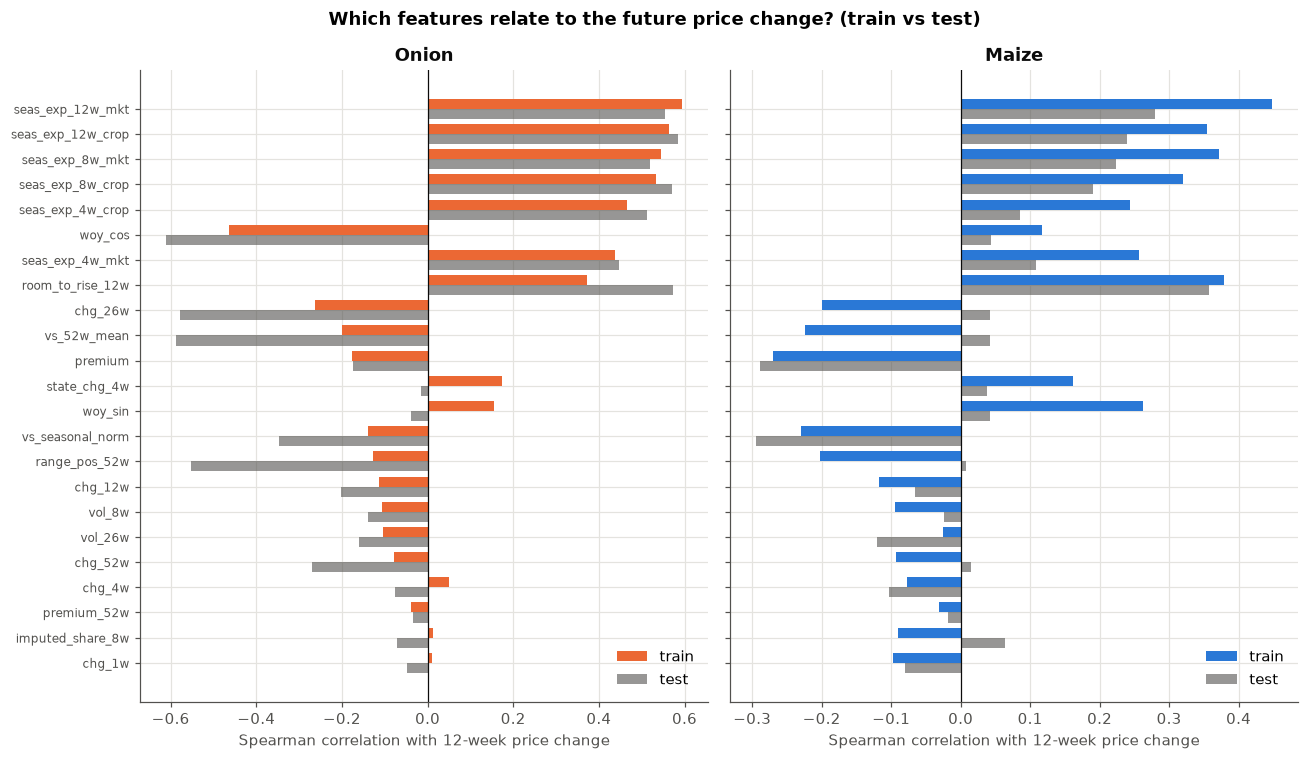

,Onion train,Onion test,Maize train,Maize test
seas_exp_12w_mkt,0.59,0.55,0.45,0.28
seas_exp_12w_crop,0.56,0.59,0.35,0.24
seas_exp_8w_mkt,0.55,0.52,0.37,0.22
seas_exp_8w_crop,0.53,0.57,0.32,0.19
seas_exp_4w_crop,0.47,0.51,0.24,0.09
woy_cos,-0.46,-0.61,0.12,0.04
seas_exp_4w_mkt,0.44,0.45,0.26,0.11
room_to_rise_12w,0.37,0.57,0.38,0.36
chg_26w,-0.26,-0.58,-0.20,0.04
vs_52w_mean,-0.20,-0.59,-0.22,0.04


In [9]:
def relevance(crop, split):
    d = panel[(panel["commodity"] == crop) & (panel["split"] == split) & panel["target_12w_observed"]]
    return pd.Series({f: stats.spearmanr(d[f], d["target_12w"], nan_policy="omit").statistic for f in FEATURES_NUM})

rel = {(crop, s): relevance(crop, s) for crop in CROPS for s in ["train", "test"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
order = rel[("Onion", "train")].abs().sort_values().index
for ax, crop in zip(axes, CROPS):
    y = np.arange(len(order))
    ax.barh(y + 0.2, rel[(crop, "train")][order], height=0.4, color=CROP_COLOR[crop], label="train")
    ax.barh(y - 0.2, rel[(crop, "test")][order], height=0.4, color=MUTED, alpha=0.6, label="test")
    ax.set_yticks(y); ax.set_yticklabels(order, fontsize=8)
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_xlabel("Spearman correlation with 12-week price change"); ax.set_title(crop); ax.legend(frameon=False, loc="lower right")
fig.suptitle("Which features relate to the future price change? (train vs test)", fontweight="bold")
plt.tight_layout(); plt.show()

relevance_table = pd.DataFrame({f"{c} {s}": v for (c, s), v in rel.items()}).loc[order[::-1]].round(2)
relevance_table.head(10)

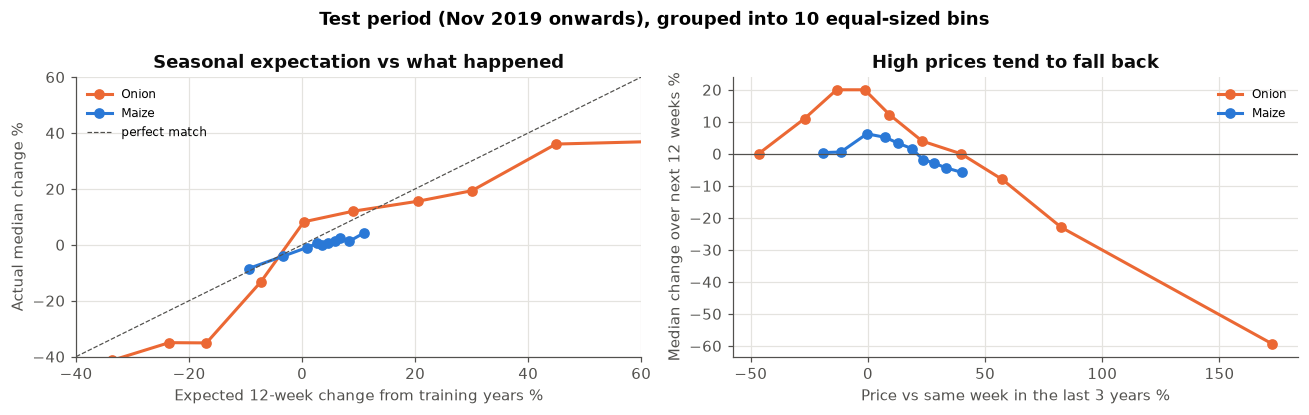

In [10]:
# Two key relationships, shown directly (test period, observed targets)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for crop in CROPS:
    d = panel[(panel["commodity"] == crop) & (panel["split"] == "test") & panel["target_12w_observed"]].dropna(
        subset=["vs_seasonal_norm", "seas_exp_12w_mkt"])
    for ax, f in zip(axes, ["seas_exp_12w_mkt", "vs_seasonal_norm"]):
        bins = pd.qcut(d[f], 10, duplicates="drop")
        b = d.groupby(bins, observed=True).agg(x=(f, "median"), y=("target_12w", "median"))
        ax.plot(100 * np.expm1(b["x"]), 100 * np.expm1(b["y"]), color=CROP_COLOR[crop], marker="o", linewidth=2, label=crop)
axes[0].plot([-40, 60], [-40, 60], color=MUTED, linewidth=0.8, linestyle="--", label="perfect match")
axes[0].set_xlim(-40, 60); axes[0].set_ylim(-40, 60)
axes[0].set_xlabel("Expected 12-week change from training years %"); axes[0].set_ylabel("Actual median change %")
axes[0].set_title("Seasonal expectation vs what happened")
axes[1].axhline(0, color=MUTED, linewidth=0.8)
axes[1].set_xlabel("Price vs same week in the last 3 years %"); axes[1].set_ylabel("Median change over next 12 weeks %")
axes[1].set_title("High prices tend to fall back")
for ax in axes: ax.legend(frameon=False, fontsize=8)
fig.suptitle(f"Test period ({CUT:%b %Y} onwards), grouped into 10 equal-sized bins", fontweight="bold")
plt.tight_layout(); plt.show()

**What this shows.**
- The **seasonal expectation** is the strongest single feature for onion in both periods: weeks that historically
  saw rises still tend to see rises. But the onion line in the left chart does not follow the dashed line exactly: in
  the test period the expected big rises came out smaller, and the expected falls came out bigger. The calendar alone
  over-promises, so the models need the other features too.
- **Mean reversion**: when the onion price is already far above its normal level for the time of year, it has fallen
  sharply over the next 12 weeks (by about 60% in the top bin), while prices at or a little below normal rose the
  most. Maize shows the same shape on a much smaller scale. This relationship is stronger in the test period than in
  training for onion.
- **Short-term momentum** (`chg_1w`, `chg_4w`) carries almost no information 12 weeks ahead.
- For maize the relationships are weaker, especially in the test period, so maize forecasts are expected to be less
  useful, which fits Notebook 3 (small, unreliable storage gains).

## 6. PCA: how closely do Karnataka's mandis move together? (RQ2)

**Data matrix.** For each crop: rows = weeks, columns = core markets, values = the market's **4-week log price change**.
Changes are used, not price levels, because all levels share an upward trend that would make any two markets look
related (Notebook 3, Section 8).

**Standardisation.** Each market's column is scaled to mean 0 and standard deviation 1, using **training weeks
only**. Without this, the jumpiest markets would dominate the components simply because their numbers are larger.

**Missing values.** After scaling, a missing value is set to 0, which is that market's training mean. Weeks are kept
only if at least half the markets reported. Test weeks are scaled and projected with the training means, standard
deviations and components; nothing is refitted on the test period.

**How the reduced representation is evaluated**
1. Explained variance and the scree plot (how many components are needed?).
2. Loadings (what does each component mean?).
3. **Stability:** how much of the **test-period** variation do the training components explain?
4. **Usefulness:** Notebook 5 compares forecasting models with and without the PC scores.

In [11]:
def market_matrix(crop):
    p = panel[panel["commodity"] == crop]
    m = p.pivot(index="week", columns="market", values="log_price").diff(4)
    divisions = p.drop_duplicates("market").set_index("market")["division"]
    order = sorted(m.columns, key=lambda c: (DIV_ORDER.index(divisions[c]), c))
    return m[order], divisions

pca_info = {}
score_tables = []
for crop in CROPS:
    m, divisions = market_matrix(crop)
    train_m = m[m.index + pd.Timedelta(weeks=MAX_H) < CUT]
    mu, sd = train_m.mean(), train_m.std()
    z = (m - mu) / sd
    enough = z.notna().mean(axis=1) >= 0.5
    z_filled = z.fillna(0)
    is_train = (z.index + pd.Timedelta(weeks=MAX_H) < CUT) & enough
    pca = PCA(random_state=SEED).fit(z_filled[is_train])
    # make the loadings easy to read: flip each component so its loadings are mostly positive
    signs = np.sign(pca.components_.sum(axis=1)); signs[signs == 0] = 1
    components = pca.components_ * signs[:, None]
    scores = pd.DataFrame(z_filled.to_numpy() @ components[:3].T, index=z.index, columns=["pc1", "pc2", "pc3"])
    scores[~enough.to_numpy()] = np.nan
    score_tables.append(scores.assign(commodity=crop).reset_index())
    pca_info[crop] = dict(pca=pca, components=components, z=z_filled, enough=enough, is_train=is_train,
                          markets=list(m.columns), divisions=divisions, n_train=int(is_train.sum()))
    print(f"{crop}: {len(m.columns)} markets, {int(is_train.sum())} training weeks used to fit PCA")

Onion: 18 markets, 486 training weeks used to fit PCA
Maize: 48 markets, 486 training weeks used to fit PCA


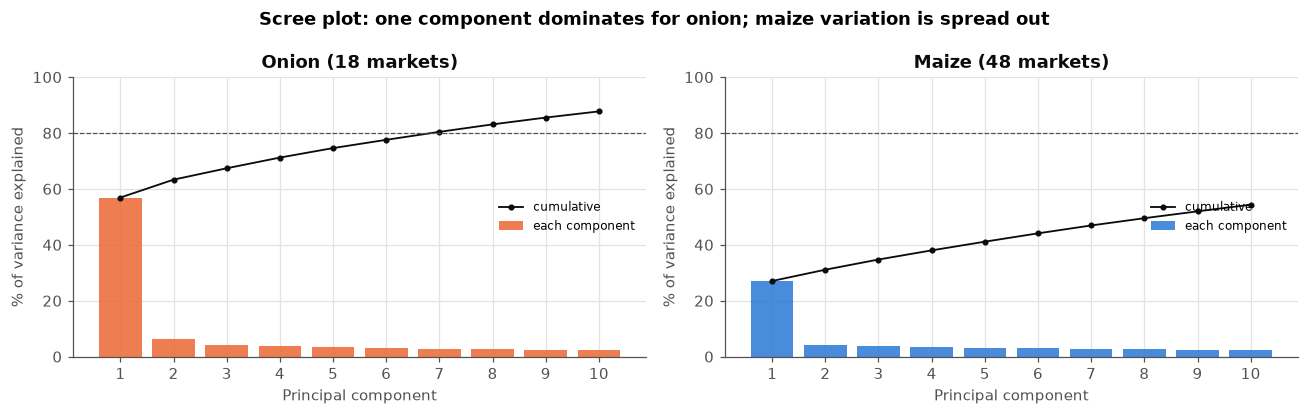

,crop,markets,PC1 %,PC1-3 %,components for 80%,components with eigenvalue > 1 (Kaiser)
0,Onion,18,56.9,67.4,7,2
1,Maize,48,27.1,34.7,25,11


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
var_rows = []
for ax, crop in zip(axes, CROPS):
    ratio = pca_info[crop]["pca"].explained_variance_ratio_
    eig = pca_info[crop]["pca"].explained_variance_
    k = min(10, len(ratio))
    ax.bar(range(1, k + 1), 100 * ratio[:k], color=CROP_COLOR[crop], alpha=0.85, label="each component")
    ax.plot(range(1, k + 1), 100 * np.cumsum(ratio)[:k], color=INK, marker="o", markersize=3, linewidth=1.2, label="cumulative")
    ax.axhline(80, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_xticks(range(1, k + 1)); ax.set_xlabel("Principal component"); ax.set_ylabel("% of variance explained")
    ax.set_ylim(0, 100); ax.set_title(f"{crop} ({len(ratio)} markets)"); ax.legend(frameon=False, fontsize=8, loc="center right")
    var_rows.append({"crop": crop, "markets": len(ratio), "PC1 %": 100 * ratio[0], "PC1-3 %": 100 * ratio[:3].sum(),
                     "components for 80%": int(np.searchsorted(np.cumsum(ratio), 0.80) + 1),
                     "components with eigenvalue > 1 (Kaiser)": int((eig > 1).sum())})
fig.suptitle("Scree plot: one component dominates for onion; maize variation is spread out", fontweight="bold")
plt.tight_layout(); plt.show()
pd.DataFrame(var_rows).round(1)

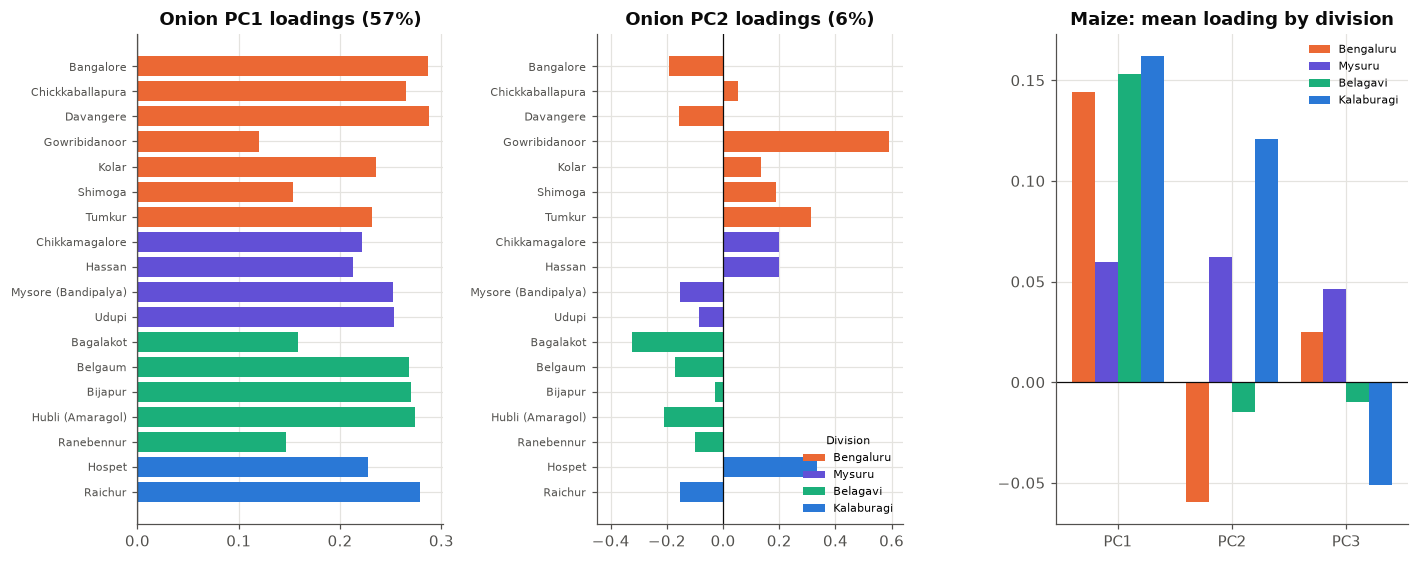

Onion: mean loading by division
             PC1   PC2   PC3
division                    
Bengaluru   0.23  0.13 -0.01
Mysuru      0.23  0.04 -0.01
Belagavi    0.22 -0.17  0.05
Kalaburagi  0.25  0.09  0.01


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})
info = pca_info["Onion"]
y = np.arange(len(info["markets"]))
for ax, pc in zip(axes[:2], [0, 1]):
    load = info["components"][pc]
    ax.barh(y, load, color=[DIV_COLOR[info["divisions"][mk]] for mk in info["markets"]])
    ax.set_yticks(y); ax.set_yticklabels(info["markets"], fontsize=7); ax.invert_yaxis()
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_title(f"Onion PC{pc + 1} loadings ({100 * info['pca'].explained_variance_ratio_[pc]:.0f}%)")
for div in DIV_ORDER:
    axes[1].bar(0, 0, color=DIV_COLOR[div], label=div)
axes[1].legend(frameon=False, fontsize=7, loc="lower right", title="Division", title_fontsize=7)

# Maize: average loading by division, since 48 bars would be unreadable
info = pca_info["Maize"]
load = pd.DataFrame(info["components"][:3].T, index=info["markets"], columns=["PC1", "PC2", "PC3"])
load["division"] = load.index.map(info["divisions"])
by_div = load.groupby("division")[["PC1", "PC2", "PC3"]].mean().loc[DIV_ORDER]
x = np.arange(3)
for i, div in enumerate(DIV_ORDER):
    axes[2].bar(x + (i - 1.5) * 0.2, by_div.loc[div], width=0.2, color=DIV_COLOR[div], label=div)
axes[2].set_xticks(x); axes[2].set_xticklabels(["PC1", "PC2", "PC3"]); axes[2].axhline(0, color=INK, linewidth=0.8)
axes[2].set_title("Maize: mean loading by division"); axes[2].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

onion_load = pd.DataFrame(pca_info["Onion"]["components"][:3].T, index=pca_info["Onion"]["markets"], columns=["PC1", "PC2", "PC3"])
onion_load["division"] = onion_load.index.map(pca_info["Onion"]["divisions"])
print("Onion: mean loading by division")
print(onion_load.groupby("division")[["PC1", "PC2", "PC3"]].mean().loc[DIV_ORDER].round(2).to_string())

**Interpreting the loadings.**
- **PC1 is a statewide market factor.** Every market loads positively and by a similar amount: PC1 is high in weeks
  when prices rise everywhere at once. For onion it explains well over half of all variation, so onion prices across
  Karnataka are driven mainly by one common force (national supply, the Maharashtra crop, export policy), not by
  local conditions.
- **PC2 and PC3 are contrasts**: some markets load positively and others negatively, and each explains only a few
  percent. For onion, PC2 is dominated by one market, Gowribidanoor, whose prices moved differently from the rest
  (Notebook 3, Section 8); beyond that it separates the Belagavi-division markets (negative) from most others. For
  maize, PC2 separates Kalaburagi and Mysuru division markets from Bengaluru division markets: a regional contrast.
  Small components like these are partly noise, which is why Notebook 5 tests whether they help.
- **Maize is different:** PC1 explains only about a quarter of the variation, and many components are needed to reach
  80%. Maize prices are more local: each market moves partly on its own. This answers RQ2: **onion mandis are tightly
  integrated; maize mandis much less so.**

,crop,period,weeks,variance explained by 1 PC(s) %,variance explained by 3 PC(s) %,variance explained by 5 PC(s) %
0,Onion,train,486,56.9,67.4,74.6
1,Onion,test,332,51.9,60.3,65.7
2,Maize,train,486,27.1,34.7,41.1
3,Maize,test,256,28.6,33.5,36.9


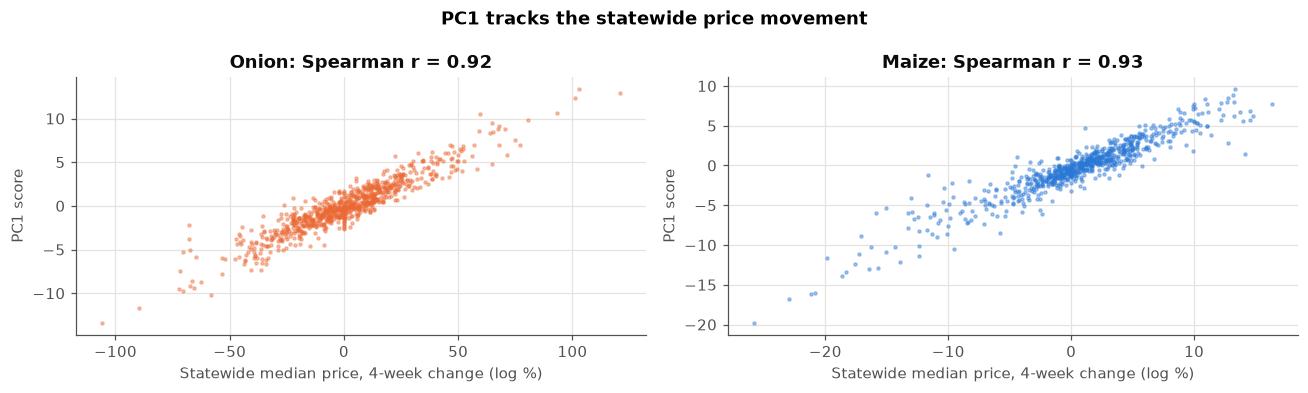

In [14]:
# Stability: how much of the variation in each period do the TRAINING components explain?
rows = []
for crop in CROPS:
    info = pca_info[crop]
    z = info["z"]
    is_test = (z.index >= CUT) & info["enough"].to_numpy()
    for label, mask in [("train", info["is_train"]), ("test", is_test)]:
        X = z[mask].to_numpy()
        X = X - X.mean(axis=0)
        total = (X ** 2).sum()
        row = {"crop": crop, "period": label, "weeks": int(mask.sum())}
        for k in [1, 3, 5]:
            V = info["components"][:k]
            recon = X @ V.T @ V
            row[f"variance explained by {k} PC(s) %"] = 100 * (1 - ((X - recon) ** 2).sum() / total)
        rows.append(row)
stability = pd.DataFrame(rows).round(1)
display(stability)

# PC1 against the statewide price change: is PC1 really the "statewide factor"?
scores = pd.concat(score_tables, ignore_index=True)
state = panel.groupby(["commodity", "week"])["state_chg_4w"].first().reset_index()
check = scores.merge(state, on=["commodity", "week"]).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, crop in zip(axes, CROPS):
    d = check[check["commodity"] == crop]
    r = stats.spearmanr(d["pc1"], d["state_chg_4w"]).statistic
    ax.scatter(d["state_chg_4w"] * 100, d["pc1"], s=4, alpha=0.4, color=CROP_COLOR[crop])
    ax.set_xlabel("Statewide median price, 4-week change (log %)"); ax.set_ylabel("PC1 score")
    ax.set_title(f"{crop}: Spearman r = {r:.2f}")
fig.suptitle("PC1 tracks the statewide price movement", fontweight="bold")
plt.tight_layout(); plt.show()

**Stability result.** The components learned on 2010-2019 explain a similar share of the variation in the test
period. For onion, the single statewide factor holds up after 2019 (the market structure did not change), so PC
scores built from the training fit are safe to use as features for the test period. For maize the share is lower in
both periods, as expected for a crop whose markets move more independently.

**Choice of components.** The scree plot has its elbow after PC1 for both crops, the Kaiser rule keeps 2 for onion but
many for maize, and the 80% rule would need many components. Since the purpose here is forecasting features, not
compressing the data, the first **3 components** are kept: PC1 (the statewide factor) plus two regional contrasts.
Notebook 5 tests whether they actually improve the forecast.

## 7. Assemble and save

In [15]:
panel = panel.merge(scores, on=["commodity", "week"], how="left")

FEATURES = FEATURES_NUM + ["pc1", "pc2", "pc3", "week_of_year", "month", "was_imputed", "division", "market"]
KEYS = ["commodity", "market", "district", "division", "week", "split", "price", "price_filled", "log_price"]
TARGETS = [c for h in HORIZONS for c in (f"target_{h}w", f"target_{h}w_observed")]
features = panel[list(dict.fromkeys(KEYS + FEATURES + TARGETS))]
features = features[features["log_price"].notna()]
features.to_csv("../data/features.csv", index=False)

dictionary = pd.DataFrame([
    ("woy_sin, woy_cos", "A Calendar", "sin and cos of 2*pi*week/52", "Position in the crop year; week 52 sits next to week 1"),
    ("week_of_year, month", "A Calendar", "ISO week (1-52), calendar month", "Season, for tree models"),
    ("chg_1w ... chg_52w", "B Momentum", "log price now - log price k weeks ago", "Direction and length of the recent trend"),
    ("vs_52w_mean", "C Level", "log price - mean log price of last 52 weeks", "Is the price high compared with the last year?"),
    ("vs_seasonal_norm", "C Level", "log price - mean of same week 1, 2, 3 years ago", "Is the price high for this time of year? (high prices tend to fall)"),
    ("range_pos_52w", "C Level", "(price - 52-week min) / (52-week max - min)", "Near the top or bottom of the past year's range?"),
    ("seas_exp_hw_crop", "D Seasonal", "median h-week log change from this week of year, training years, all markets", "What usually happens next at this time of year"),
    ("seas_exp_hw_mkt", "D Seasonal", "same, for this market (crop value if < 5 training years)", "Local seasonal pattern"),
    ("room_to_rise_12w", "E Combined", "seas_exp_12w_mkt - vs_seasonal_norm", "Seasonal rise still to come, after allowing for how high the price already is"),
    ("vol_8w, vol_26w", "F Risk", "SD of weekly log changes over 8 / 26 weeks", "How jumpy the market is; risk of storing"),
    ("premium", "G Spatial", "log price - log statewide median", "Is this market dear or cheap compared with the state now?"),
    ("premium_52w", "G Spatial", "mean premium over last 52 weeks", "This market's usual position compared with the state"),
    ("state_chg_4w", "G Spatial", "4-week change of statewide median", "Where the whole state's price is heading"),
    ("division, market", "G Spatial", "categories (one-hot encoded in Notebook 5)", "Fixed local differences"),
    ("imputed_share_8w, was_imputed", "H Data quality", "share of last 8 weeks filled in Notebook 2", "How much to trust the recent history"),
    ("pc1, pc2, pc3", "PCA", "scores of 4-week changes on training-fitted components", "Statewide factor and regional contrasts"),
], columns=["feature", "group", "formula", "why it is meaningful"])
dictionary.to_csv("../data/feature_dictionary.csv", index=False)

load_rows = []
for crop in CROPS:
    info = pca_info[crop]
    for i, mk in enumerate(info["markets"]):
        load_rows.append({"commodity": crop, "market": mk, "division": info["divisions"][mk],
                          **{f"PC{j + 1}": info["components"][j][i] for j in range(3)}})
pd.DataFrame(load_rows).to_csv("../data/pca_loadings.csv", index=False)
pd.DataFrame(var_rows).merge(stability.pivot(index="crop", columns="period",
                                             values="variance explained by 3 PC(s) %").add_prefix("PC1-3 % ").reset_index(),
                             on="crop").to_csv("../data/pca_variance.csv", index=False)

print(f"Saved data/features.csv: {len(features):,} rows x {features.shape[1]} columns")
has_target = features["target_12w"].notna() & features["split"].isin(["train", "test"])
print("Rows with a 12-week target, by split (%):",
      (features.loc[has_target, "split"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Saved data/feature_dictionary.csv, data/pca_loadings.csv, data/pca_variance.csv")
dictionary

Saved data/features.csv: 46,774 rows x 44 columns
Rows with a 12-week target, by split (%): {'train': 70.1, 'test': 29.9}
Saved data/feature_dictionary.csv, data/pca_loadings.csv, data/pca_variance.csv


,feature,group,formula,why it is meaningful
0,"woy_sin, woy_cos",A Calendar,sin and cos of 2*pi*week/52,Position in the crop year; week 52 sits next t...
1,"week_of_year, month",A Calendar,"ISO week (1-52), calendar month","Season, for tree models"
2,chg_1w ... chg_52w,B Momentum,log price now - log price k weeks ago,Direction and length of the recent trend
3,vs_52w_mean,C Level,log price - mean log price of last 52 weeks,Is the price high compared with the last year?
4,vs_seasonal_norm,C Level,"log price - mean of same week 1, 2, 3 years ago",Is the price high for this time of year? (high...
5,range_pos_52w,C Level,(price - 52-week min) / (52-week max - min),Near the top or bottom of the past year's range?
6,seas_exp_hw_crop,D Seasonal,median h-week log change from this week of yea...,What usually happens next at this time of year
7,seas_exp_hw_mkt,D Seasonal,"same, for this market (crop value if < 5 train...",Local seasonal pattern
8,room_to_rise_12w,E Combined,seas_exp_12w_mkt - vs_seasonal_norm,"Seasonal rise still to come, after allowing fo..."
9,"vol_8w, vol_26w",F Risk,SD of weekly log changes over 8 / 26 weeks,How jumpy the market is; risk of storing


## 8. Summary

| Result | Evidence | Used in |
| --- | --- | --- |
| Chronological 70/30 split with a 12-week purge; seasonal features and PCA fitted on training rows only | Sections 1, 3, 6 | Notebook 5: every model uses this split |
| 31 features in 8 groups, each tied to a question a farmer or trader would ask | Section 3, `feature_dictionary.csv` | Notebook 5 |
| The seasonal expectation and the "price vs normal" features carry most of the signal; short-term momentum carries little | Section 5 | Feature importance checks in Notebook 5 |
| Several features overlap strongly | Section 4 | Ridge regression and the with/without PCA comparison |
| **RQ2:** onion mandis move together (PC1 explains most of the variation); maize mandis are much more local | Section 6 | PC scores as features; interpretation in the report |
| The PCA structure learned on 2010-2019 still holds after 2019 | Section 6, stability table | Safe to use PC features in the test period |